# Phase 1 EDA

Exploratory analysis and leakage-relevant sanity checks on the frozen dataset in
`data/processed/`, per PHASE1_SPEC.md's EDA requirements (Week 3).

This notebook is read-only with respect to the pipeline: it never writes back to
`data/processed/`. It answers open findings 1 and 2 from PHASE1_SPEC.md with real,
measured numbers - no placeholder values.

Sections:
1. Setup
2. ADF stationarity tests (justifies the log-return target)
3. Jump base rate (open finding 2)
4. Distributional moments
5. Feature redundancy / correlation
6. Persistence baselines (Section 11f - open finding 1)
7. Regime coverage across splits


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

import config
import build_dataset

aligned = pd.read_csv("data/processed/aligned_dataset.csv", index_col="Date", parse_dates=True)
train = pd.read_csv("data/processed/train.csv", index_col="Date", parse_dates=True)
val = pd.read_csv("data/processed/val.csv", index_col="Date", parse_dates=True)
test = pd.read_csv("data/processed/test.csv", index_col="Date", parse_dates=True)

print(f"aligned: {aligned.shape[0]} rows, {aligned.index.min().date()} to {aligned.index.max().date()}")
print(f"train:   {train.shape[0]} rows")
print(f"val:     {val.shape[0]} rows")
print(f"test:    {test.shape[0]} rows")


aligned: 2057 rows, 2018-02-12 to 2025-12-30
train:   1535 rows
val:     262 rows
test:    260 rows


## 2. ADF stationarity tests

Section 3.4.1 of the proposal justifies using log-returns instead of raw closing
prices on the grounds that returns are stationary and prices are not. This checks
that claim against the actual data rather than taking it on faith.

Raw price *levels* aren't stored in `aligned_dataset.csv` (build_dataset.py's pinned
output is the 19 engineered features plus the 3 targets, not raw prices), so the
level series is rebuilt directly from `data/raw/` using `build_dataset._align` -
the same internal function `leakage_audit.py` already reuses for its own checks.


In [2]:
raw_aligned = build_dataset._align(build_dataset.RAW_DIR)

adf_level = adfuller(raw_aligned["btc_close"].dropna())
adf_return = adfuller(aligned["btc_log_return"].dropna())

print(f"ADF on BTC price level : statistic={adf_level[0]:.4f}, p-value={adf_level[1]:.6f}")
print(f"ADF on BTC log-return  : statistic={adf_return[0]:.4f}, p-value={adf_return[1]:.6f}")
print()
print("Null hypothesis: the series has a unit root (is non-stationary).")
print(f"Level series stationary at 5%?     {adf_level[1] < 0.05}")
print(f"Log-return series stationary at 5%? {adf_return[1] < 0.05}")


Forward-filling 11 on-chain gap day(s): {'chain_active_addresses': 5, 'chain_hash_rate': 2, 'chain_transaction_count': 2, 'chain_difficulty': 2}
ADF on BTC price level : statistic=-1.0211, p-value=0.745505
ADF on BTC log-return  : statistic=-20.3634, p-value=0.000000

Null hypothesis: the series has a unit root (is non-stationary).
Level series stationary at 5%?     False
Log-return series stationary at 5%? True


## 3. Jump base rate (open finding 2)

PHASE1_SPEC.md: *"Must be measured in Week 3. It sets the BCE loss weighting for
the Beta Agent's jump head in Phase 3."* This is that measurement.


In [3]:
jump_rate = {
    "overall": aligned["beta_target_jump"].mean(),
    "train": train["beta_target_jump"].mean(),
    "val": val["beta_target_jump"].mean(),
    "test": test["beta_target_jump"].mean(),
}
for name, rate in jump_rate.items():
    print(f"{name:<8} jump rate = {rate:.4%}")

print()
print(f"Suggested BCE pos_weight for Phase 3 (train-split rate, (1-p)/p): "
      f"{(1 - jump_rate['train']) / jump_rate['train']:.2f}")


overall  jump rate = 2.4793%
train    jump rate = 2.6710%
val      jump rate = 2.6718%
test     jump rate = 1.1538%

Suggested BCE pos_weight for Phase 3 (train-split rate, (1-p)/p): 36.44


## 4. Distributional moments

Skew and kurtosis (excess, normal = 0) per feature. Chapter 2 motivates log-returns
partly on the grounds that Bitcoin is fat-tailed - this checks whether that shows up
as excess kurtosis in the actual engineered features.


In [4]:
moments = pd.DataFrame({
    "mean": aligned[config.FEATURE_ORDER].mean(),
    "std": aligned[config.FEATURE_ORDER].std(),
    "skew": aligned[config.FEATURE_ORDER].skew(),
    "excess_kurtosis": aligned[config.FEATURE_ORDER].kurt(),
})
moments.round(4)


,mean,std,skew,excess_kurtosis
btc_log_return,0.0011,0.0396,-0.8681,12.4926
eth_log_return,0.0006,0.0525,-0.6411,9.9752
sp500_log_return,0.0005,0.0121,-0.6430,15.6638
gold_log_return,0.0006,0.0098,-0.3571,4.1418
dxy_log_return,0.0000,0.0041,-0.1829,1.9533
vix_log_return,-0.0003,0.0781,1.0992,5.9960
btc_realised_vol_14d,0.0358,0.0174,2.1165,9.0130
corr_btc_eth_30d,0.8326,0.1005,-1.1271,2.2674
corr_btc_sp500_30d,0.2547,0.2731,-0.3917,-0.5036
corr_btc_gold_30d,0.1048,0.2258,-0.1092,-0.2636


## 5. Feature redundancy / correlation

Correlation across the 19 engineered features. High correlation between two
features doesn't break anything on its own, but it's worth knowing about before
Phase 2, since redundant inputs can slow training without adding signal.


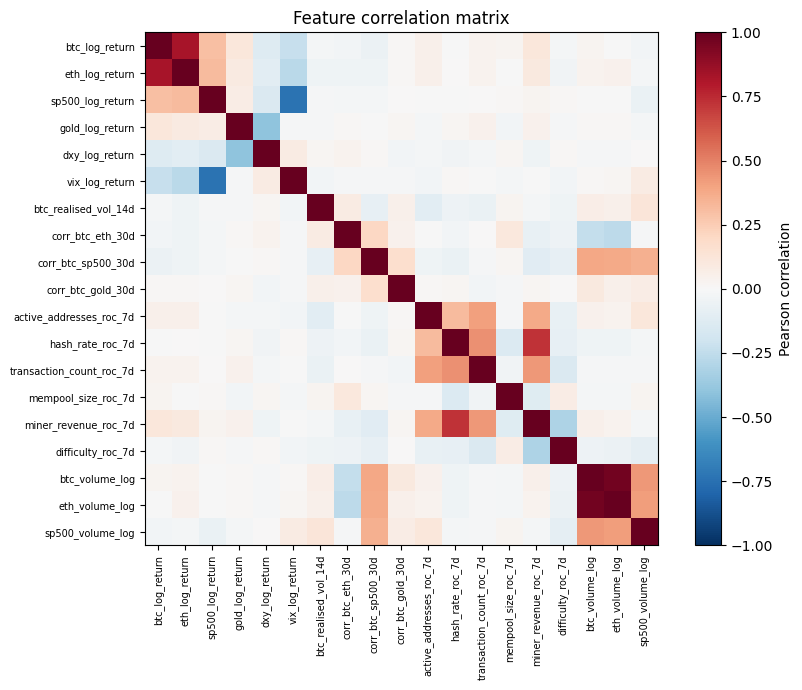

In [5]:
corr_matrix = aligned[config.FEATURE_ORDER].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(config.FEATURE_ORDER)))
ax.set_yticks(range(len(config.FEATURE_ORDER)))
ax.set_xticklabels(config.FEATURE_ORDER, rotation=90, fontsize=7)
ax.set_yticklabels(config.FEATURE_ORDER, fontsize=7)
fig.colorbar(im, label="Pearson correlation")
ax.set_title("Feature correlation matrix")
plt.tight_layout()
plt.show()


In [6]:
pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
high_corr = pairs[pairs.abs() > 0.6].sort_values(key=abs, ascending=False)
print(f"{len(high_corr)} feature pair(s) with |correlation| > 0.6:")
high_corr


4 feature pair(s) with |correlation| > 0.6:


btc_volume_log    eth_volume_log          0.962436
btc_log_return    eth_log_return          0.821802
sp500_log_return  vix_log_return         -0.737433
hash_rate_roc_7d  miner_revenue_roc_7d    0.723048
dtype: float64

## 6. Persistence baselines (Section 11f - open finding 1)

The most important section. Reports the naive-persistence R² for both targets:
predicting tomorrow's value with today's already-known value, no model involved.

Open finding 1: the Beta Agent's volatility target structurally overlaps its own
input feature (`btc_realised_vol_14d` at day *t* and `beta_target_vol`, which is
that same rolling statistic one day later, share all but one of their 14
observations). This should show up here as a very high persistence R² - high by
construction, not because anything was learned.

The Alpha Agent's target (`alpha_target`, tomorrow's log-return) faces no such
overlap and should show near-zero persistence, which is the expected signature of
an efficiently-priced return series.


In [7]:
def persistence_r2(naive_pred, actual):
    mask = naive_pred.notna() & actual.notna()
    naive_pred, actual = naive_pred[mask], actual[mask]
    ss_res = ((actual - naive_pred) ** 2).sum()
    ss_tot = ((actual - actual.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot


vol_r2 = persistence_r2(aligned["btc_realised_vol_14d"], aligned["beta_target_vol"])
alpha_r2 = persistence_r2(aligned["btc_log_return"], aligned["alpha_target"])

print(f"Beta Agent (volatility) naive-persistence R²:  {vol_r2:.4f}")
print(f"Alpha Agent (log-return) naive-persistence R²: {alpha_r2:.4f}")
print()
print("Any reported Beta Agent result MUST be compared against the "
      f"{vol_r2:.4f} baseline above, not reported as a raw R² on its own "
      "(PHASE1_SPEC.md open finding 1).")


Beta Agent (volatility) naive-persistence R²:  0.9171
Alpha Agent (log-return) naive-persistence R²: -1.0553

Any reported Beta Agent result MUST be compared against the 0.9171 baseline above, not reported as a raw R² on its own (PHASE1_SPEC.md open finding 1).


## 7. Regime coverage

Confirms train, validation, and test each contain both bull and bear stretches -
required for H3 to be testable at all (a test set that's one directional regime
can't distinguish "the risk engine helped" from "the market happened to be calm").


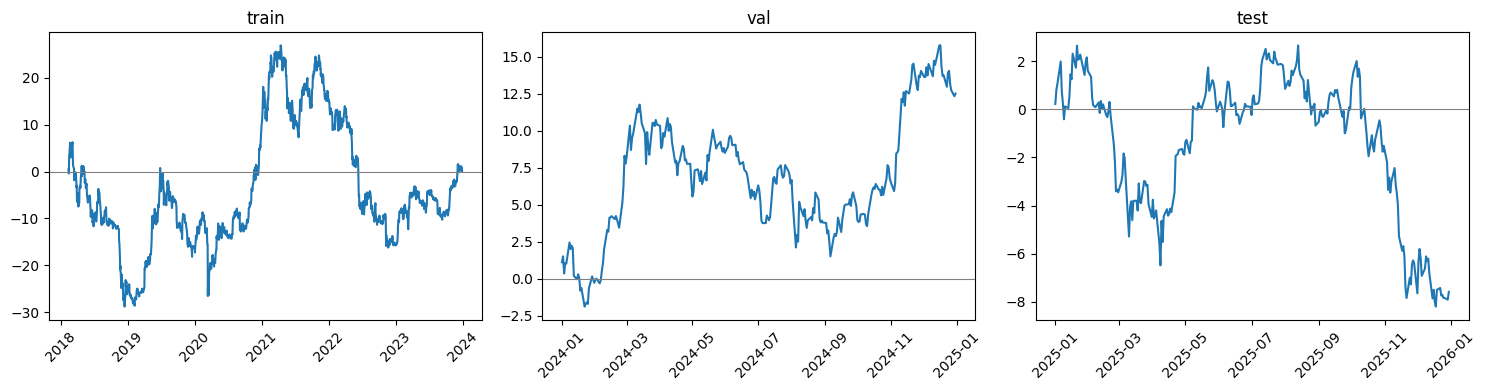

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, (name, split) in zip(axes, [("train", train), ("val", val), ("test", test)]):
    cum_return = split["btc_log_return"].cumsum()
    ax.plot(cum_return.index, cum_return.values)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


In [9]:
for name, split in [("train", train), ("val", val), ("test", test)]:
    cum_return = split["btc_log_return"].cumsum()
    pct_up_days = (split["btc_log_return"] > 0).mean()
    print(
        f"{name:<6} cumulative log-return {cum_return.iloc[-1]:+.3f}  "
        f"peak {cum_return.max():+.3f}  trough {cum_return.min():+.3f}  "
        f"up-days {pct_up_days:.1%}"
    )


train  cumulative log-return +0.000  peak +26.858  trough -28.754  up-days 49.8%
val    cumulative log-return +12.498  peak +15.755  trough -1.889  up-days 49.6%
test   cumulative log-return -7.595  peak +2.667  trough -8.208  up-days 48.8%
